# 02 - Backtest Core (first minimal prototype)

Verifies the full execution workflow on real Dukascopy tick data:

    raw ticks -> M15 BID candles -> simple strategy -> signal after candle close
    -> entry on first real tick at/after signal availability -> tick-by-tick SL/TP
    -> trade log -> performance summary

This is **not** a production framework. It is deliberately minimal and inspectable.
No classes, no databases, no commissions, no slippage, no portfolio logic, and
PnL is in price terms only. Source data is read from `../data/` and never modified.

## Constants

The strategy is intentionally meaningless; it exists only to exercise the engine.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)

In [2]:
DATA_PATH = "../data/XAUUSD_DUKAS_2025_01_ticks.csv"

SYMBOL = "XAUUSD"
TIMEFRAME = "15min"

BACKTEST_START_UTC = "2025-01-31 00:00:00+00:00"
BACKTEST_END_UTC   = "2025-01-31 22:00:00+00:00"

STOP_DISTANCE = 5.0
TAKE_PROFIT_DISTANCE = 10.0

SOURCE_COLUMNS = ["date", "time", "bid", "ask", "bid_volume", "ask_volume"]
BAR = pd.Timedelta(TIMEFRAME)  # signal availability offset after a candle closes

print("Backtest range:", BACKTEST_START_UTC, "->", BACKTEST_END_UTC)
print("Stop distance:", STOP_DISTANCE, "| Take profit distance:", TAKE_PROFIT_DISTANCE)

Backtest range: 2025-01-31 00:00:00+00:00 -> 2025-01-31 22:00:00+00:00
Stop distance: 5.0 | Take profit distance: 10.0


## Load and filter ticks (READ-ONLY)

Timestamps are parsed as UTC with no shifting, exactly as established in Task 01.
Ticks are filtered to the backtest range in memory only. Natural gaps are not errors.

In [3]:
start = pd.Timestamp(BACKTEST_START_UTC)
end = pd.Timestamp(BACKTEST_END_UTC)

raw = pd.read_csv(DATA_PATH, header=None, names=SOURCE_COLUMNS)
raw["timestamp"] = pd.to_datetime(
    raw["date"] + " " + raw["time"],
    format="%Y.%m.%d %H:%M:%S.%f",
).dt.tz_localize("UTC")

mask = (raw["timestamp"] >= start) & (raw["timestamp"] <= end)
ticks_real = raw.loc[mask, ["timestamp", "bid", "ask"]].reset_index(drop=True)
del raw

print("Ticks in range:", len(ticks_real))
print("First tick:", ticks_real["timestamp"].iloc[0])
print("Last  tick:", ticks_real["timestamp"].iloc[-1])

Ticks in range: 322548
First tick: 2025-01-31 00:00:00.044000+00:00
Last  tick: 2025-01-31 21:59:56.320000+00:00


## M15 BID candles

frequency = 15min, label = left, closed = left. Empty intervals are dropped, never filled.
A candle labeled 10:00 covers `[10:00, 10:15)`.

In [4]:
def build_candles(ticks, timeframe=TIMEFRAME):
    bid = ticks.set_index("timestamp")["bid"]
    ohlc = bid.resample(timeframe, label="left", closed="left").ohlc()
    return ohlc.dropna(how="all")


candles_real = build_candles(ticks_real)

print("M15 BID candles (non-empty):", len(candles_real))
display(candles_real.head(3))
display(candles_real.tail(3))

M15 BID candles (non-empty): 88


,open,high,low,close
timestamp,,,,
2025-01-31 00:00:00+00:00,2795.95,2799.38,2795.01,2797.49
2025-01-31 00:15:00+00:00,2797.47,2798.57,2796.66,2797.57
2025-01-31 00:30:00+00:00,2797.59,2798.30,2795.55,2796.03


,open,high,low,close
timestamp,,,,
2025-01-31 21:15:00+00:00,2801.52,2802.30,2799.89,2800.86
2025-01-31 21:30:00+00:00,2800.93,2801.18,2798.14,2799.47
2025-01-31 21:45:00+00:00,2799.41,2801.93,2796.61,2798.09


## Signals

A signal is generated only from a completed candle and becomes available at
`candle_start + 15min`. The last candle's signal may exist but have no tick to execute on.

In [5]:
def candles_to_signals(candles):
    rows = []
    for candle_start, row in candles.iterrows():
        if row["close"] > row["open"]:
            direction = "LONG"
        elif row["close"] < row["open"]:
            direction = "SHORT"
        else:
            continue
        rows.append(
            {
                "signal_candle_start": candle_start,
                "signal_available_time": candle_start + BAR,
                "direction": direction,
            }
        )
    return pd.DataFrame(rows, columns=["signal_candle_start", "signal_available_time", "direction"])


signals_real = candles_to_signals(candles_real)

print("Signals:", len(signals_real))
print("By direction:", signals_real["direction"].value_counts().to_dict())
display(signals_real.head(5))

Signals: 88
By direction: {'LONG': 45, 'SHORT': 43}


,signal_candle_start,signal_available_time,direction
0,2025-01-31 00:00:00+00:00,2025-01-31 00:15:00+00:00,LONG
1,2025-01-31 00:15:00+00:00,2025-01-31 00:30:00+00:00,LONG
2,2025-01-31 00:30:00+00:00,2025-01-31 00:45:00+00:00,SHORT
3,2025-01-31 00:45:00+00:00,2025-01-31 01:00:00+00:00,SHORT
4,2025-01-31 01:00:00+00:00,2025-01-31 01:15:00+00:00,LONG


## Backtest engine

Per tick, the deterministic order is:

1. If a position is open, evaluate SL/TP on this tick.
2. Then evaluate signals whose availability time has been reached.
3. A position opened earlier on the same tick that closed is not possible here, but a
   position closed on this tick may be replaced by a new entry using the same tick.

Exits use the executable side (BID for LONG, ASK for SHORT) at the actual observed
tick price, so a jump through SL/TP exits at the real tick, not the configured level.

In [6]:
def run_backtest(ticks, candles, stop_distance=STOP_DISTANCE, take_profit_distance=TAKE_PROFIT_DISTANCE):
    signals = candles_to_signals(candles)

    t = ticks.sort_values("timestamp", kind="stable").reset_index(drop=True)
    timestamps = t["timestamp"].tolist()
    bid = t["bid"].to_numpy(dtype="float64")
    ask = t["ask"].to_numpy(dtype="float64")

    s = signals.sort_values("signal_available_time", kind="stable").reset_index(drop=True)
    s_time = s["signal_available_time"].tolist()
    s_dir = s["direction"].tolist()
    s_start = s["signal_candle_start"].tolist()
    n_signals = len(s)

    trades = []
    position = None
    next_signal = 0

    def close_position(i, exit_price, reason):
        nonlocal position
        d = position
        if d["direction"] == "LONG":
            pnl_price = exit_price - d["entry_price"]
        else:
            pnl_price = d["entry_price"] - exit_price
        trades.append(
            {
                "trade_id": len(trades) + 1,
                "direction": d["direction"],
                "signal_candle_start": d["signal_candle_start"],
                "signal_available_time": d["signal_available_time"],
                "entry_time": d["entry_time"],
                "entry_bid": d["entry_bid"],
                "entry_ask": d["entry_ask"],
                "entry_price": d["entry_price"],
                "stop_loss": d["stop_loss"],
                "take_profit": d["take_profit"],
                "exit_time": timestamps[i],
                "exit_bid": bid[i],
                "exit_ask": ask[i],
                "exit_price": exit_price,
                "exit_reason": reason,
                "pnl_price": pnl_price,
                "duration_seconds": (timestamps[i] - d["entry_time"]).total_seconds(),
                "spread_at_entry": d["entry_ask"] - d["entry_bid"],
                "spread_at_exit": ask[i] - bid[i],
            }
        )
        position = None

    for i in range(len(t)):
        ti = timestamps[i]

        # 1) evaluate exit on this tick first
        if position is not None:
            if position["direction"] == "LONG":
                if bid[i] <= position["stop_loss"]:
                    close_position(i, bid[i], "SL")
                elif bid[i] >= position["take_profit"]:
                    close_position(i, bid[i], "TP")
            else:
                if ask[i] >= position["stop_loss"]:
                    close_position(i, ask[i], "SL")
                elif ask[i] <= position["take_profit"]:
                    close_position(i, ask[i], "TP")

        # 2) then consume signals that are due at this tick
        while next_signal < n_signals and s_time[next_signal] <= ti:
            if position is None:
                direction = s_dir[next_signal]
                if direction == "LONG":
                    entry_price = ask[i]
                    stop_loss = entry_price - stop_distance
                    take_profit = entry_price + take_profit_distance
                else:
                    entry_price = bid[i]
                    stop_loss = entry_price + stop_distance
                    take_profit = entry_price - take_profit_distance
                position = {
                    "direction": direction,
                    "signal_candle_start": s_start[next_signal],
                    "signal_available_time": s_time[next_signal],
                    "entry_time": ti,
                    "entry_bid": bid[i],
                    "entry_ask": ask[i],
                    "entry_price": entry_price,
                    "stop_loss": stop_loss,
                    "take_profit": take_profit,
                }
            next_signal += 1

    # close any open position at the end of the selected data
    if position is not None:
        i = len(t) - 1
        exit_price = bid[i] if position["direction"] == "LONG" else ask[i]
        close_position(i, exit_price, "END_OF_DATA")

    return pd.DataFrame(trades)

## Synthetic execution tests (in-memory only)

Small deterministic checks of the execution rules before trusting the real-data run.
No files are created.

In [7]:
def _utc(values):
    return pd.to_datetime(values, format="mixed").dt.tz_localize("UTC")


def _ticks_df(rows):
    df = pd.DataFrame(rows, columns=["timestamp", "bid", "ask"])
    df["timestamp"] = _utc(df["timestamp"])
    return df


def _candles_df(rows):
    df = pd.DataFrame(rows, columns=["candle_start", "open", "high", "low", "close"])
    df["candle_start"] = _utc(df["candle_start"])
    return df.set_index("candle_start")


test_results = {}


def report_test(number, passed, detail=""):
    name = f"EXECUTION TEST {number}"
    test_results[name] = bool(passed)
    print(f"{name}: {'PASS' if passed else 'FAIL'}")
    if not passed and detail:
        print("   detail:", detail)


# TEST 1 - LONG enters at ASK, takes profit on BID
c1 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
t1 = _ticks_df([("2025-01-01 10:15", 101.0, 101.5), ("2025-01-01 10:16", 112.0, 112.5)])
r1 = run_backtest(t1, c1)
ok1 = (
    len(r1) == 1
    and r1.loc[0, "direction"] == "LONG"
    and r1.loc[0, "entry_price"] == r1.loc[0, "entry_ask"] == 101.5
    and r1.loc[0, "exit_price"] == r1.loc[0, "exit_bid"] == 112.0
    and r1.loc[0, "exit_reason"] == "TP"
)
report_test(1, ok1, r1.to_dict("records"))

# TEST 2 - LONG stop loss is triggered on BID
c2 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
t2 = _ticks_df([("2025-01-01 10:15", 100.0, 100.5), ("2025-01-01 10:16", 95.0, 95.5)])
r2 = run_backtest(t2, c2)
ok2 = (
    len(r2) == 1
    and r2.loc[0, "direction"] == "LONG"
    and r2.loc[0, "entry_price"] == r2.loc[0, "entry_ask"] == 100.5
    and r2.loc[0, "exit_price"] == r2.loc[0, "exit_bid"] == 95.0
    and r2.loc[0, "exit_reason"] == "SL"
)
report_test(2, ok2, r2.to_dict("records"))

# TEST 3 - SHORT enters at BID, takes profit on ASK
c3 = _candles_df([("2025-01-01 10:00", 101.0, 101.5, 99.5, 100.0)])
t3 = _ticks_df([("2025-01-01 10:15", 100.0, 100.5), ("2025-01-01 10:16", 88.5, 89.0)])
r3 = run_backtest(t3, c3)
ok3 = (
    len(r3) == 1
    and r3.loc[0, "direction"] == "SHORT"
    and r3.loc[0, "entry_price"] == r3.loc[0, "entry_bid"] == 100.0
    and r3.loc[0, "exit_price"] == r3.loc[0, "exit_ask"] == 89.0
    and r3.loc[0, "exit_reason"] == "TP"
)
report_test(3, ok3, r3.to_dict("records"))

# TEST 4 - SHORT stop loss is triggered on ASK
c4 = _candles_df([("2025-01-01 10:00", 101.0, 101.5, 99.5, 100.0)])
t4 = _ticks_df([("2025-01-01 10:15", 100.0, 100.5), ("2025-01-01 10:16", 105.5, 106.0)])
r4 = run_backtest(t4, c4)
ok4 = (
    len(r4) == 1
    and r4.loc[0, "direction"] == "SHORT"
    and r4.loc[0, "entry_price"] == r4.loc[0, "entry_bid"] == 100.0
    and r4.loc[0, "exit_price"] == r4.loc[0, "exit_ask"] == 106.0
    and r4.loc[0, "exit_reason"] == "SL"
)
report_test(4, ok4, r4.to_dict("records"))

# TEST 5 - gap through SL exits at the actual observed tick, not the configured SL
c5 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
t5 = _ticks_df([("2025-01-01 10:15", 100.0, 100.5), ("2025-01-01 10:16", 90.0, 90.5)])
r5 = run_backtest(t5, c5)
ok5 = (
    len(r5) == 1
    and r5.loc[0, "exit_reason"] == "SL"
    and r5.loc[0, "stop_loss"] == 95.5
    and r5.loc[0, "exit_price"] == 90.0
    and r5.loc[0, "exit_price"] != r5.loc[0, "stop_loss"]
)
report_test(5, ok5, r5.to_dict("records"))

EXECUTION TEST 1: PASS
EXECUTION TEST 2: PASS


EXECUTION TEST 3: PASS
EXECUTION TEST 4: PASS
EXECUTION TEST 5: PASS


## Edge-case execution tests (in-memory only)

Additional deterministic checks of the position rule, event ordering, natural gaps,
end-of-data handling, look-ahead protection, and ignored signals.
The engine logic is unchanged; these tests only exercise it.

In [8]:
edge_results = {}


def report_edge(number, passed, detail=""):
    name = f"EDGE TEST {number}"
    edge_results[name] = bool(passed)
    print(f"{name}: {'PASS' if passed else 'FAIL'}")
    if not passed and detail:
        print("   detail:", detail)


# EDGE 1 - a signal arriving while a position is open is ignored, not queued
ec1 = _candles_df([
    ("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0),
    ("2025-01-01 10:15", 101.0, 101.5, 99.5, 100.0),
])
et1 = _ticks_df([
    ("2025-01-01 10:15", 100.5, 101.0),
    ("2025-01-01 10:30", 100.6, 101.1),
    ("2025-01-01 10:31", 112.0, 112.5),
])
er1 = run_backtest(et1, ec1)
ok_e1 = (
    len(er1) == 1
    and er1.loc[0, "direction"] == "LONG"
    and er1.loc[0, "exit_reason"] == "TP"
)
report_edge(1, ok_e1, er1.to_dict("records"))

# EDGE 2 - position closes and a new signal enters on the same tick (exit first)
ec2 = _candles_df([
    ("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0),
    ("2025-01-01 10:15", 101.0, 101.5, 99.5, 100.0),
])
et2 = _ticks_df([
    ("2025-01-01 10:15", 100.0, 100.5),
    ("2025-01-01 10:30", 111.0, 111.5),
    ("2025-01-01 10:31", 100.0, 100.5),
])
er2 = run_backtest(et2, ec2)
ok_e2 = (
    len(er2) == 2
    and er2.loc[0, "direction"] == "LONG"
    and er2.loc[0, "exit_reason"] == "TP"
    and er2.loc[1, "direction"] == "SHORT"
    and er2.loc[1, "entry_time"] == er2.loc[0, "exit_time"]
    and er2.loc[1, "entry_price"] == er2.loc[1, "entry_bid"] == 111.0
)
report_edge(2, ok_e2, er2.to_dict("records"))

# EDGE 3 - natural gap: entry uses the next real tick after availability
ec3 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
et3 = _ticks_df([
    ("2025-01-01 10:40", 100.0, 100.5),
    ("2025-01-01 10:41", 95.0, 95.5),
])
er3 = run_backtest(et3, ec3)
ok_e3 = (
    len(er3) == 1
    and er3.loc[0, "entry_time"] == pd.Timestamp("2025-01-01 10:40:00+00:00")
    and er3.loc[0, "entry_time"] > er3.loc[0, "signal_available_time"]
)
report_edge(3, ok_e3, er3.to_dict("records"))

# EDGE 4 - open position closed at END_OF_DATA using the final executable side
ec4 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
et4 = _ticks_df([
    ("2025-01-01 10:15", 100.0, 100.5),
    ("2025-01-01 10:16", 100.2, 100.7),
])
er4 = run_backtest(et4, ec4)
ok_e4 = (
    len(er4) == 1
    and er4.loc[0, "exit_reason"] == "END_OF_DATA"
    and er4.loc[0, "exit_price"] == er4.loc[0, "exit_bid"] == 100.2
    and er4.loc[0, "exit_time"] == pd.Timestamp("2025-01-01 10:16:00+00:00")
)
report_edge(4, ok_e4, er4.to_dict("records"))

# EDGE 5 - no look-ahead: a tick before availability is never used for entry
ec5 = _candles_df([("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0)])
et5 = _ticks_df([
    ("2025-01-01 10:14", 100.0, 100.1),
    ("2025-01-01 10:15:30", 100.2, 100.7),
])
er5 = run_backtest(et5, ec5)
ok_e5 = (
    len(er5) == 1
    and er5.loc[0, "entry_time"] == pd.Timestamp("2025-01-01 10:15:30+00:00")
    and er5.loc[0, "entry_price"] == er5.loc[0, "entry_ask"] == 100.7
)
report_edge(5, ok_e5, er5.to_dict("records"))

# EDGE 6 - a doji candle (close == open) produces no signal and no trade
ec6 = _candles_df([("2025-01-01 10:00", 100.0, 100.5, 99.5, 100.0)])
et6 = _ticks_df([("2025-01-01 10:15", 100.0, 100.5)])
er6 = run_backtest(et6, ec6)
ok_e6 = (
    len(candles_to_signals(ec6)) == 0
    and len(er6) == 0
)
report_edge(6, ok_e6, {"signals": len(candles_to_signals(ec6)), "trades": len(er6)})

# EDGE 7 - several overdue signals at the first tick: only the first executes
ec7 = _candles_df([
    ("2025-01-01 10:00", 100.0, 101.5, 99.5, 101.0),
    ("2025-01-01 10:15", 101.0, 101.5, 99.5, 100.0),
    ("2025-01-01 10:30", 100.0, 101.5, 99.5, 101.0),
])
et7 = _ticks_df([
    ("2025-01-01 11:00", 100.0, 100.5),
    ("2025-01-01 11:01", 95.0, 95.5),
])
er7 = run_backtest(et7, ec7)
ok_e7 = (
    len(er7) == 1
    and er7.loc[0, "signal_candle_start"] == pd.Timestamp("2025-01-01 10:00:00+00:00")
    and er7.loc[0, "direction"] == "LONG"
)
report_edge(7, ok_e7, er7.to_dict("records"))

EDGE TEST 1: PASS
EDGE TEST 2: PASS
EDGE TEST 3: PASS
EDGE TEST 4: PASS


EDGE TEST 5: PASS
EDGE TEST 6: PASS
EDGE TEST 7: PASS


## Run on real data

Signals are generated from candles; entry happens on the first real tick at/after the
signal availability time. A signal whose first opportunity occurs while a position is
open is ignored and never queued.

In [9]:
trades = run_backtest(ticks_real, candles_real)

print("Trades:", len(trades))
display(trades)

Trades: 7


,trade_id,direction,signal_candle_start,signal_available_time,entry_time,entry_bid,entry_ask,entry_price,stop_loss,take_profit,exit_time,exit_bid,exit_ask,exit_price,exit_reason,pnl_price,duration_seconds,spread_at_entry,spread_at_exit
0,1,LONG,2025-01-31 00:00:00+00:00,2025-01-31 00:15:00+00:00,2025-01-31 00:15:01.237000+00:00,2797.47,2798.07,2798.07,2793.07,2808.07,2025-01-31 06:55:24.853000+00:00,2792.91,2793.38,2792.91,SL,-5.16,24023.616,0.60,0.47
1,2,SHORT,2025-01-31 06:45:00+00:00,2025-01-31 07:00:00+00:00,2025-01-31 07:00:00.037000+00:00,2792.68,2793.16,2792.68,2797.68,2782.68,2025-01-31 07:20:03.286000+00:00,2797.16,2797.70,2797.70,SL,-5.02,1203.249,0.48,0.54
2,3,LONG,2025-01-31 07:15:00+00:00,2025-01-31 07:30:00+00:00,2025-01-31 07:30:00.071000+00:00,2799.49,2800.41,2800.41,2795.41,2810.41,2025-01-31 08:22:03.135000+00:00,2795.39,2795.97,2795.39,SL,-5.02,3123.064,0.92,0.58
3,4,SHORT,2025-01-31 08:15:00+00:00,2025-01-31 08:30:00+00:00,2025-01-31 08:30:00.114000+00:00,2793.39,2794.09,2793.39,2798.39,2783.39,2025-01-31 11:40:07.759000+00:00,2797.45,2798.43,2798.43,SL,-5.04,11407.645,0.70,0.98
4,5,LONG,2025-01-31 11:30:00+00:00,2025-01-31 11:45:00+00:00,2025-01-31 11:45:00.098000+00:00,2796.88,2797.78,2797.78,2792.78,2807.78,2025-01-31 13:40:01.514000+00:00,2807.82,2808.28,2807.82,TP,10.04,6901.416,0.90,0.46
5,6,LONG,2025-01-31 13:30:00+00:00,2025-01-31 13:45:00+00:00,2025-01-31 13:45:00.118000+00:00,2807.05,2807.68,2807.68,2802.68,2817.68,2025-01-31 18:18:40.593000+00:00,2802.50,2802.91,2802.50,SL,-5.18,16420.475,0.63,0.41
6,7,SHORT,2025-01-31 18:15:00+00:00,2025-01-31 18:30:00+00:00,2025-01-31 18:30:00.011000+00:00,2799.57,2800.05,2799.57,2804.57,2789.57,2025-01-31 21:59:56.320000+00:00,2798.09,2800.01,2800.01,END_OF_DATA,-0.44,12596.309,0.48,1.92


## Performance summary (price terms only)

No commissions, no slippage, no account currency conversion.

In [10]:
n_trades = len(trades)

if n_trades:
    longs = int((trades["direction"] == "LONG").sum())
    shorts = int((trades["direction"] == "SHORT").sum())
    winners = int((trades["pnl_price"] > 0).sum())
    losers = int((trades["pnl_price"] < 0).sum())
    breakevens = int((trades["pnl_price"] == 0).sum())
    win_rate = winners / n_trades
    total_pnl = trades["pnl_price"].sum()
    avg_pnl = trades["pnl_price"].mean()
    avg_winner = trades.loc[trades["pnl_price"] > 0, "pnl_price"].mean()
    avg_loser = trades.loc[trades["pnl_price"] < 0, "pnl_price"].mean()
    largest_winner = trades["pnl_price"].max()
    largest_loser = trades["pnl_price"].min()
    tp_exits = int((trades["exit_reason"] == "TP").sum())
    sl_exits = int((trades["exit_reason"] == "SL").sum())
    eod_exits = int((trades["exit_reason"] == "END_OF_DATA").sum())
else:
    longs = shorts = winners = losers = breakevens = 0
    win_rate = total_pnl = avg_pnl = avg_winner = avg_loser = float("nan")
    largest_winner = largest_loser = float("nan")
    tp_exits = sl_exits = eod_exits = 0

print("Total trades:     ", n_trades)
print("Long trades:      ", longs)
print("Short trades:     ", shorts)
print("Winning trades:   ", winners)
print("Losing trades:    ", losers)
print("Breakeven trades: ", breakevens)
print("Win rate:         ", win_rate)
print("Total pnl_price:  ", total_pnl)
print("Average pnl_price:", avg_pnl)
print("Average winner:   ", avg_winner)
print("Average loser:    ", avg_loser)
print("Largest winner:   ", largest_winner)
print("Largest loser:    ", largest_loser)
print("TP exits:         ", tp_exits)
print("SL exits:         ", sl_exits)
print("END_OF_DATA exits:", eod_exits)

Total trades:      7
Long trades:       4
Short trades:      3
Winning trades:    1
Losing trades:     6
Breakeven trades:  0
Win rate:          0.14285714285714285
Total pnl_price:   -15.820000000000164
Average pnl_price: -2.2600000000000233
Average winner:    10.039999999999964
Average loser:     -4.310000000000021
Largest winner:    10.039999999999964
Largest loser:     -5.179999999999836
TP exits:          1
SL exits:          5
END_OF_DATA exits: 1


## Equity curve

Cumulative sum of trade PnL in price terms. This is not account balance.

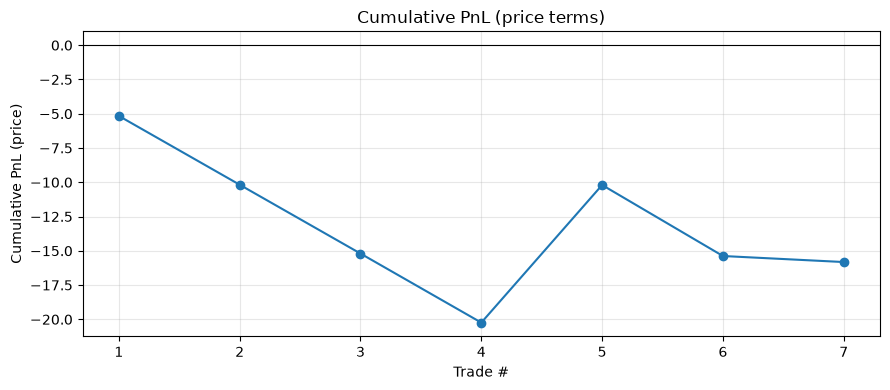

In [11]:
equity = trades.sort_values("trade_id")["pnl_price"].cumsum().reset_index(drop=True)
equity.index = equity.index + 1

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(equity.index, equity.values, marker="o")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Cumulative PnL (price terms)")
ax.set_xlabel("Trade #")
ax.set_ylabel("Cumulative PnL (price)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Manual inspection

`inspect_trade(trade_id)` prints the trade, its signal candle, its entry/exit ticks,
and raw ticks around entry and exit.

In [12]:
def _ticks_around(ts, seconds=3):
    lo = ts - pd.Timedelta(seconds=seconds)
    hi = ts + pd.Timedelta(seconds=seconds)
    window = ticks_real.loc[(ticks_real["timestamp"] >= lo) & (ticks_real["timestamp"] <= hi)]
    return window[["timestamp", "bid", "ask"]]


def inspect_trade(trade_id):
    row = trades.loc[trades["trade_id"] == trade_id]
    if row.empty:
        print("trade_id", trade_id, "not found")
        return
    tr = row.iloc[0]

    print("=" * 64)
    print(f"TRADE {int(tr['trade_id'])}  {tr['direction']}")
    print("=" * 64)
    print("signal_candle_start :", tr["signal_candle_start"])
    print("signal_available    :", tr["signal_available_time"])
    print("entry_time          :", tr["entry_time"])
    print("exit_time           :", tr["exit_time"])
    print("entry bid/ask       :", tr["entry_bid"], "/", tr["entry_ask"])
    print("entry_price         :", tr["entry_price"])
    print("stop_loss           :", tr["stop_loss"])
    print("take_profit         :", tr["take_profit"])
    print("exit bid/ask        :", tr["exit_bid"], "/", tr["exit_ask"])
    print("exit_price          :", tr["exit_price"], f"({tr['exit_reason']})")
    print("pnl_price           :", tr["pnl_price"])
    print("duration_seconds    :", tr["duration_seconds"])
    print("spread entry/exit   :", tr["spread_at_entry"], "/", tr["spread_at_exit"])

    print("\nSIGNAL CANDLE OHLC:")
    display(candles_real.loc[[tr["signal_candle_start"]]])

    print("ENTRY TICK:")
    display(ticks_real.loc[ticks_real["timestamp"] == tr["entry_time"]])
    print("EXIT TICK:")
    display(ticks_real.loc[ticks_real["timestamp"] == tr["exit_time"]])

    print("RAW TICKS AROUND ENTRY (+/- 3s):")
    display(_ticks_around(tr["entry_time"], 3))
    print("RAW TICKS AROUND EXIT (+/- 3s):")
    display(_ticks_around(tr["exit_time"], 3))


# inspect every executed trade
for trade_id in trades["trade_id"]:
    inspect_trade(trade_id)

TRADE 1  LONG
signal_candle_start : 2025-01-31 00:00:00+00:00
signal_available    : 2025-01-31 00:15:00+00:00
entry_time          : 2025-01-31 00:15:01.237000+00:00
exit_time           : 2025-01-31 06:55:24.853000+00:00
entry bid/ask       : 2797.47 / 2798.07
entry_price         : 2798.07
stop_loss           : 2793.07
take_profit         : 2808.07
exit bid/ask        : 2792.91 / 2793.38
exit_price          : 2792.91 (SL)
pnl_price           : -5.160000000000309
duration_seconds    : 24023.616
spread entry/exit   : 0.6000000000003638 / 0.47000000000025466

SIGNAL CANDLE OHLC:


,open,high,low,close
timestamp,,,,
2025-01-31 00:00:00+00:00,2795.95,2799.38,2795.01,2797.49


ENTRY TICK:


,timestamp,bid,ask
2128,2025-01-31 00:15:01.237000+00:00,2797.47,2798.07


EXIT TICK:


...

,timestamp,bid,ask
322547,2025-01-31 21:59:56.320000+00:00,2798.09,2800.01


RAW TICKS AROUND ENTRY (+/- 3s):


,timestamp,bid,ask
263183,2025-01-31 18:29:57.104000+00:00,2799.59,2800.07
263184,2025-01-31 18:29:57.208000+00:00,2799.61,2800.11
263185,2025-01-31 18:29:57.313000+00:00,2799.59,2799.99
263186,2025-01-31 18:29:57.364000+00:00,2799.59,2800.03
263187,2025-01-31 18:29:57.416000+00:00,2799.59,2800.05
...,...,...,...
263239,2025-01-31 18:30:02.396000+00:00,2799.62,2800.11
263240,2025-01-31 18:30:02.499000+00:00,2799.66,2800.14
263241,2025-01-31 18:30:02.602000+00:00,2799.62,2800.11
263242,2025-01-31 18:30:02.744000+00:00,2799.64,2800.14


RAW TICKS AROUND EXIT (+/- 3s):


,timestamp,bid,ask
322545,2025-01-31 21:59:54.478000+00:00,2798.07,2799.89
322546,2025-01-31 21:59:55.615000+00:00,2798.07,2799.91
322547,2025-01-31 21:59:56.320000+00:00,2798.09,2800.01


## Correctness checks

Programmatic invariants for the real-data run.

In [13]:
def pf(value):
    return "PASS" if value else "FAIL"


entry_ts = pd.to_datetime(trades["entry_time"])
avail_ts = pd.to_datetime(trades["signal_available_time"])
exit_ts = pd.to_datetime(trades["exit_time"])

entry_ge_avail = bool((entry_ts >= avail_ts).all())
exit_ge_entry = bool((exit_ts >= entry_ts).all())

long_mask = trades["direction"] == "LONG"
short_mask = trades["direction"] == "SHORT"

long_entry_ok = bool((trades.loc[long_mask, "entry_price"] == trades.loc[long_mask, "entry_ask"]).all())
short_entry_ok = bool((trades.loc[short_mask, "entry_price"] == trades.loc[short_mask, "entry_bid"]).all())
long_exit_ok = bool((trades.loc[long_mask, "exit_price"] == trades.loc[long_mask, "exit_bid"]).all())
short_exit_ok = bool((trades.loc[short_mask, "exit_price"] == trades.loc[short_mask, "exit_ask"]).all())

ids_unique = bool(trades["trade_id"].is_unique)
valid_reasons = bool(trades["exit_reason"].isin(["SL", "TP", "END_OF_DATA"]).all())

ordered = trades.assign(_entry=entry_ts, _exit=exit_ts).sort_values("_entry").reset_index(drop=True)
if len(ordered) > 1:
    no_overlap = bool(
        (ordered["_entry"].iloc[1:].reset_index(drop=True)
         >= ordered["_exit"].iloc[:-1].reset_index(drop=True)).all()
    )
else:
    no_overlap = True

required_cols = [
    "trade_id", "direction", "signal_candle_start", "signal_available_time",
    "entry_time", "entry_bid", "entry_ask", "entry_price", "stop_loss", "take_profit",
    "exit_time", "exit_bid", "exit_ask", "exit_price", "exit_reason", "pnl_price",
    "duration_seconds", "spread_at_entry", "spread_at_exit",
]
log_complete = bool(
    set(required_cols).issubset(trades.columns)
    and ids_unique
    and valid_reasons
)

print("entry_time >= signal_available_time:", pf(entry_ge_avail))
print("exit_time >= entry_time:            ", pf(exit_ge_entry))
print("LONG entry_price == entry_ask:      ", pf(long_entry_ok))
print("SHORT entry_price == entry_bid:     ", pf(short_entry_ok))
print("LONG exit_price == exit_bid:        ", pf(long_exit_ok))
print("SHORT exit_price == exit_ask:       ", pf(short_exit_ok))
print("no overlapping positions:           ", pf(no_overlap))
print("trade ids unique:                   ", pf(ids_unique))
print("valid exit_reason:                  ", pf(valid_reasons))

entry_time >= signal_available_time:

 PASS
exit_time >= entry_time:             PASS
LONG entry_price == entry_ask:       PASS
SHORT entry_price == entry_bid:      PASS
LONG exit_price == exit_bid:         PASS
SHORT exit_price == exit_ask:        PASS
no overlapping positions:            PASS
trade ids unique:                    PASS
valid exit_reason:                   PASS


## Audit table

One row per executed trade with per-trade invariant flags.

In [14]:
audit = pd.DataFrame({
    "trade_id": trades["trade_id"].to_numpy(),
    "direction": trades["direction"].to_numpy(),
    "signal_candle_start": trades["signal_candle_start"].to_numpy(),
    "signal_available_time": trades["signal_available_time"].to_numpy(),
    "entry_time": trades["entry_time"].to_numpy(),
    "exit_time": trades["exit_time"].to_numpy(),
    "entry_price": trades["entry_price"].to_numpy(),
    "exit_price": trades["exit_price"].to_numpy(),
    "exit_reason": trades["exit_reason"].to_numpy(),
    "pnl_price": trades["pnl_price"].to_numpy(),
    "duration_s": trades["duration_seconds"].to_numpy(),
    "spread_entry": trades["spread_at_entry"].to_numpy(),
    "spread_exit": trades["spread_at_exit"].to_numpy(),
})

audit["timing_ok"] = (
    (pd.to_datetime(trades["entry_time"]).to_numpy() >= pd.to_datetime(trades["signal_available_time"]).to_numpy())
    & (pd.to_datetime(trades["exit_time"]).to_numpy() >= pd.to_datetime(trades["entry_time"]).to_numpy())
)
audit["entry_side_ok"] = np.where(
    trades["direction"].to_numpy() == "LONG",
    trades["entry_price"].to_numpy() == trades["entry_ask"].to_numpy(),
    trades["entry_price"].to_numpy() == trades["entry_bid"].to_numpy(),
)
audit["exit_side_ok"] = np.where(
    trades["direction"].to_numpy() == "LONG",
    trades["exit_price"].to_numpy() == trades["exit_bid"].to_numpy(),
    trades["exit_price"].to_numpy() == trades["exit_ask"].to_numpy(),
)
audit["reason_ok"] = trades["exit_reason"].isin(["SL", "TP", "END_OF_DATA"]).to_numpy()
audit["pnl_ok"] = np.where(
    trades["direction"].to_numpy() == "LONG",
    trades["exit_price"].to_numpy() - trades["entry_price"].to_numpy(),
    trades["entry_price"].to_numpy() - trades["exit_price"].to_numpy(),
) == trades["pnl_price"].to_numpy()

audit["audit_ok"] = (
    audit["timing_ok"]
    & audit["entry_side_ok"]
    & audit["exit_side_ok"]
    & audit["reason_ok"]
    & audit["pnl_ok"]
)

display(audit)
print("AUDIT:", pf(bool(audit["audit_ok"].all())))

,trade_id,direction,signal_candle_start,signal_available_time,entry_time,exit_time,entry_price,exit_price,exit_reason,pnl_price,duration_s,spread_entry,spread_exit,timing_ok,entry_side_ok,exit_side_ok,reason_ok,pnl_ok,audit_ok
0,1,LONG,2025-01-31 00:00:00+00:00,2025-01-31 00:15:00+00:00,2025-01-31 00:15:01.237000+00:00,2025-01-31 06:55:24.853000+00:00,2798.07,2792.91,SL,-5.16,24023.616,0.60,0.47,True,True,True,True,True,True
1,2,SHORT,2025-01-31 06:45:00+00:00,2025-01-31 07:00:00+00:00,2025-01-31 07:00:00.037000+00:00,2025-01-31 07:20:03.286000+00:00,2792.68,2797.70,SL,-5.02,1203.249,0.48,0.54,True,True,True,True,True,True
2,3,LONG,2025-01-31 07:15:00+00:00,2025-01-31 07:30:00+00:00,2025-01-31 07:30:00.071000+00:00,2025-01-31 08:22:03.135000+00:00,2800.41,2795.39,SL,-5.02,3123.064,0.92,0.58,True,True,True,True,True,True
3,4,SHORT,2025-01-31 08:15:00+00:00,2025-01-31 08:30:00+00:00,2025-01-31 08:30:00.114000+00:00,2025-01-31 11:40:07.759000+00:00,2793.39,2798.43,SL,-5.04,11407.645,0.70,0.98,True,True,True,True,True,True
4,5,LONG,2025-01-31 11:30:00+00:00,2025-01-31 11:45:00+00:00,2025-01-31 11:45:00.098000+00:00,2025-01-31 13:40:01.514000+00:00,2797.78,2807.82,TP,10.04,6901.416,0.90,0.46,True,True,True,True,True,True
5,6,LONG,2025-01-31 13:30:00+00:00,2025-01-31 13:45:00+00:00,2025-01-31 13:45:00.118000+00:00,2025-01-31 18:18:40.593000+00:00,2807.68,2802.50,SL,-5.18,16420.475,0.63,0.41,True,True,True,True,True,True
6,7,SHORT,2025-01-31 18:15:00+00:00,2025-01-31 18:30:00+00:00,2025-01-31 18:30:00.011000+00:00,2025-01-31 21:59:56.320000+00:00,2799.57,2800.01,END_OF_DATA,-0.44,12596.309,0.48,1.92,True,True,True,True,True,True


AUDIT: PASS


## Final report

In [15]:
execution_tests_pass = all(test_results.values())
edge_tests_pass = all(edge_results.values())
audit_pass = bool(audit["audit_ok"].all())
bidask_ok = long_entry_ok and short_entry_ok and long_exit_ok and short_exit_ok
core_ok = entry_ge_avail and exit_ge_entry and bidask_ok and no_overlap and log_complete
ready = execution_tests_pass and edge_tests_pass and core_ok and audit_pass

print("BACKTEST RANGE:")
print(f"  {BACKTEST_START_UTC} -> {BACKTEST_END_UTC}")
print("M15 CANDLES:", len(candles_real))
print("SIGNALS:", len(signals_real))
print("TRADES:", n_trades)
print("EXECUTION TESTS:", pf(execution_tests_pass))
print("EDGE-CASE TESTS:", pf(edge_tests_pass))
print("TIMING INVARIANT:", pf(entry_ge_avail and exit_ge_entry))
print("BID/ASK EXECUTION:", pf(bidask_ok))
print("NO OVERLAPPING POSITIONS:", pf(no_overlap))
print("TRADE LOG COMPLETE:", pf(log_complete))
print("AUDIT TABLE:", pf(audit_pass))
print("BACKTEST CORE STATUS:", "READY FOR MANUAL TRADE REVIEW" if ready else "NOT READY")
print("Note: PnL is in price terms only; this is not a production backtest engine.")

BACKTEST RANGE:
  2025-01-31 00:00:00+00:00 -> 2025-01-31 22:00:00+00:00
M15 CANDLES: 88
SIGNALS: 88
TRADES: 7
EXECUTION TESTS: PASS
EDGE-CASE TESTS: PASS
TIMING INVARIANT: PASS
BID/ASK EXECUTION: PASS
NO OVERLAPPING POSITIONS: PASS
TRADE LOG COMPLETE: PASS
AUDIT TABLE: PASS
BACKTEST CORE STATUS: READY FOR MANUAL TRADE REVIEW
Note: PnL is in price terms only; this is not a production backtest engine.
